# Excitation Survival + Temperature Analysis (vs cycles_per_group)

Interactive analysis of `ExcitationSurvivalScan` runs. Reuses the BLAS-free helpers from
`analyze_excitation_survival.py`:

- **Panel A** — survival vs `cycles_per_group` at release=0 (Wilson 68% CIs) → the
  `max_excitation_cycles` ceiling (how many back-to-back cycles WITHOUT PGC the atom survives).
- **Panel B** — recapture survival vs release time, one curve per `cycles_per_group` → the atom
  **temperature proxy** (a longer release before recapture drops = colder atom).

Survival is read at the LOW trap (RAW shot2 vs `atom_threshold_lowtrap`). Run with the
**working-BLAS `python`** kernel (numpy / h5py / mpl); matplotlib crashes in the artiq7_claude env.

In [49]:
import sys, os, glob
from pathlib import Path
_ANALYSIS_DIR = r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis"
if _ANALYSIS_DIR not in sys.path:
    sys.path.insert(0, _ANALYSIS_DIR)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%load_ext autoreload
%autoreload 2
from analyze_excitation_survival import (
    RESULTS_DIR, SURVIVAL_TARGET, find_run, load_run, survival_table, wilson, _half_release,
)
print("Results dir       :", RESULTS_DIR)
print("Survival target   :", SURVIVAL_TARGET, "(the ceiling threshold)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Results dir       : C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results
Survival target   : 0.95 (the ceiling threshold)


## 1. List recent runs

In [50]:
files = sorted(glob.glob(str(RESULTS_DIR / "**" / "*-ExcitationSurvivalScan.h5"), recursive=True),
               key=lambda f: int(os.path.basename(f).split("-")[0]))
if not files:
    print("No *-ExcitationSurvivalScan.h5 found yet.")
for f in files[-12:]:
    rid = int(os.path.basename(f).split("-")[0])
    d, s, _ = load_run(f)
    n = len(np.atleast_1d(d.get("esv_cpg", d.get("esv_total_cycles", []))))
    nl = int(np.sum(np.atleast_1d(d.get("esv_atom_loaded", [0])).astype(int)))
    print(f"RID {rid:>5} | {n:>6} pts | {nl:>5} loaded | "
          f"n_groups={s.get('n_groups','?')} | recool={s.get('recool_mode','?')}")

RID   575 |   1500 pts |  1479 loaded | n_groups=? | recool=?
RID   578 |   2079 pts |  2036 loaded | n_groups=? | recool=?
RID   644 |    176 pts |   172 loaded | n_groups=1 | recool=?
RID   647 |   3750 pts |  3629 loaded | n_groups=1 | recool=?


## 2. Select a run

Set `RID` to an int, or `None` for the latest.

In [51]:
RID = None   # <-- int or None (latest)

path = find_run(RID)
data, snap, rid = load_run(path)
table = survival_table(data)                  # filters loaded==1; keyed on cycles_per_group
cycle_counts = sorted({c for (c, r) in table})
releases = sorted({r for (c, r) in table})

print("File :", os.path.basename(path))
print(f"RID {rid} | n_groups={snap.get('n_groups')} | recool={snap.get('recool_mode')}")
print("cycles_per_group  :", cycle_counts)
print("release times (us):", releases)

File : 000000647-ExcitationSurvivalScan.h5
RID 647 | n_groups=1 | recool=None
cycles_per_group  : [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]
release times (us): [0.0, 25.0, 50.0, 75.0, 100.0]


## 3. Panel A — survival vs cycles_per_group (the `max_excitation_cycles` ceiling)

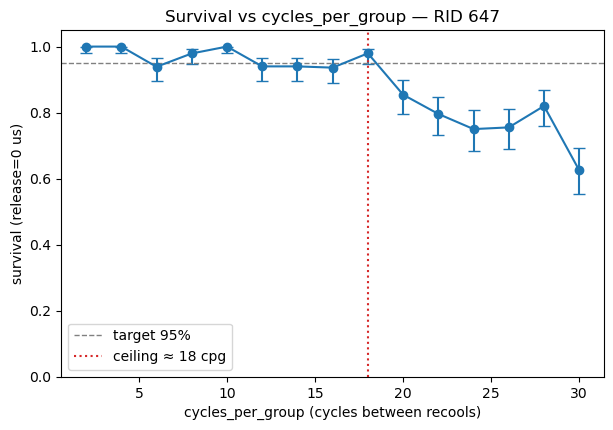

Max cycles_per_group with survival >= 95%: 18  (n_groups=1 -> 18 total cycles)


In [52]:
rel0 = 0.0 if 0.0 in releases else (releases[0] if releases else 0.0)
xs, ps, los, his = [], [], [], []
ceiling = None
for c in cycle_counts:
    kn = table.get((c, rel0))
    if not kn or kn[1] == 0:
        continue
    p, lo, hi = wilson(kn[0], kn[1])
    xs.append(c); ps.append(p)
    # clamp to >= 0: Wilson is centred on its own centre (not p), so at p=0/1
    # the error-bar distance can come out as a tiny negative from FP rounding.
    los.append(max(0.0, p - lo)); his.append(max(0.0, hi - p))
    if p >= SURVIVAL_TARGET:
        ceiling = c

fig, ax = plt.subplots(figsize=(7, 4.5))
if xs:
    ax.errorbar(xs, ps, yerr=[los, his], fmt="o-", capsize=4, color="C0")
    ax.axhline(SURVIVAL_TARGET, ls="--", color="gray", lw=1, label=f"target {SURVIVAL_TARGET:.0%}")
    if ceiling is not None:
        ax.axvline(ceiling, ls=":", color="C3", lw=1.5, label=f"ceiling ≈ {ceiling} cpg")
    ax.legend()
ax.set_xlabel("cycles_per_group (cycles between recools)")
ax.set_ylabel(f"survival (release={rel0:g} us)")
ax.set_ylim(0, 1.05)
ax.set_title(f"Survival vs cycles_per_group — RID {rid}")
plt.show()

n_groups = int(snap.get("n_groups", 1))
if ceiling is not None:
    print(f"Max cycles_per_group with survival >= {SURVIVAL_TARGET:.0%}: {ceiling}  "
          f"(n_groups={n_groups} -> {ceiling * n_groups} total cycles)")
else:
    print("Survival never reached the target at release=0 -- lower SURVIVAL_TARGET or check recool/loading.")

## 4. Panel B — recapture vs release (temperature proxy)

cycles_per_group=    2: half-recapture release = 72.6 us
cycles_per_group=    4: half-recapture release = 65.1 us
cycles_per_group=    6: half-recapture release = 63.8 us
cycles_per_group=    8: half-recapture release = 86.8 us
cycles_per_group=   10: half-recapture release = 75.0 us
cycles_per_group=   12: half-recapture release = 56.4 us
cycles_per_group=   14: half-recapture release = 73.6 us
cycles_per_group=   16: half-recapture release = 57.4 us
cycles_per_group=   18: half-recapture release = 57.9 us
cycles_per_group=   20: half-recapture release = 42.7 us
cycles_per_group=   22: half-recapture release = 58.1 us
cycles_per_group=   24: half-recapture release = 56.1 us
cycles_per_group=   26: half-recapture release = 46.0 us
cycles_per_group=   28: half-recapture release = 33.0 us
cycles_per_group=   30: half-recapture release = 50.0 us


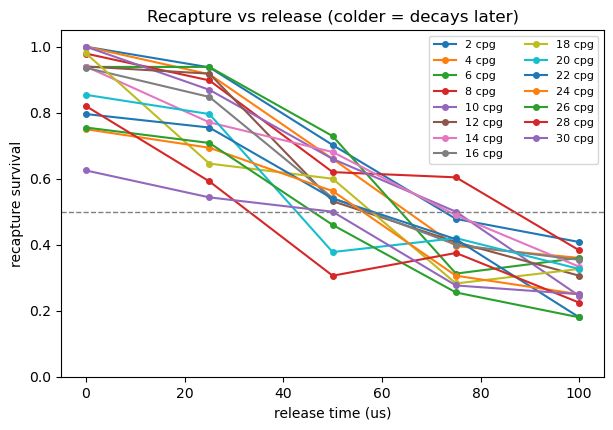

In [53]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c in cycle_counts:
    rx, ry = [], []
    for r in releases:
        kn = table.get((c, r))
        if kn and kn[1] > 0:
            rx.append(r); ry.append(kn[0] / kn[1])
    if len(rx) >= 2:
        ax.plot(rx, ry, "o-", label=f"{c} cpg", lw=1.5, ms=4)
        half = _half_release(rx, ry)
        print(f"cycles_per_group={c:>5}: half-recapture release = " + (f"{half:.1f} us" if half is not None else "n/a"))
ax.axhline(0.5, ls="--", color="gray", lw=1)
ax.set_xlabel("release time (us)")
ax.set_ylabel("recapture survival")
ax.set_ylim(0, 1.05)
ax.set_title("Recapture vs release (colder = decays later)")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 5. (optional) one-shot PNG via the script

`analyze(path)` writes a 2-panel PNG next to the `.h5`.

In [54]:
# from analyze_excitation_survival import analyze
# analyze(path)